# Break-even analysis for different $\gamma_l/\gamma_\phi$ ratios

This notebook reproduces the continuous-vs-discrete break-even plot for $\alpha=7$ at $\gamma_l/\gamma_\phi = 0.1, 1, 10$.

The x-axis is $\gamma_l$ and each run uses $\gamma_\phi = \gamma_l / (\gamma_l/\gamma_\phi)$, so the ratio-1 panel is the symmetric case from Figure 8.

In [1]:
import sys
from pathlib import Path

import dill
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from qutip import basis, coherent, displace, fidelity, squeeze, tensor

ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from continuous import ContinuousProtocol

PLOTS_DIR = ROOT / "plots"
RESULTS_DIR = ROOT / "results"
PLOTS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

In [ ]:
d = 16
m_i = 16
m_c = 8
alpha = 7
N = 200
squeezed = -0.8

In [3]:
mpl.rcParams["text.usetex"] = False
mpl.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}"
mpl.rcParams["font.family"] = "DejaVu Serif"
plt.style.use("bmh")
mpl.rcParams["axes.facecolor"] = "w"
plt.rcParams["font.size"] = 14
mpl.rc("xtick", labelsize=14)
mpl.rc("ytick", labelsize=14)

coherent_state = coherent(N, alpha)
proObj = ContinuousProtocol(coherent_state, res=d, m_i=m_i, m_c=m_c)
limit = (coherent_state.dag() * proObj._create_phase_parity_measurement(1) * coherent_state).full()[0][0].real

squeezed_state = displace(N, alpha) * squeeze(N, squeezed) * coherent(N, 0)
limit_sq = (squeezed_state.dag() * proObj._create_phase_parity_measurement(1) * squeezed_state).full()[0][0].real

def poisson_std_for_state(state):
    fock_dist = np.abs(np.array(state)) ** 2
    photon_numbers = np.arange(len(fock_dist))
    mean = np.sum(photon_numbers * fock_dist.transpose())
    return np.sqrt(np.sum(fock_dist.transpose() * (photon_numbers - mean) ** 2)).item()

std_coherent = poisson_std_for_state(coherent_state)
std_squeezed = poisson_std_for_state(squeezed_state)

In [4]:
# Data generation is intentionally not available in this notebook.
# Run tools/generate_break_even_gamma_ratio_alpha7.py, then load the cached pickles below.

In [5]:
result_files_by_ratio = {
    0.1: RESULTS_DIR / "break_even_alpha=7_gamma_l_over_gamma_phi=0p1_gamma_l=1em04_1em02_points=15.pkl",
    1: RESULTS_DIR / "break_even_alpha=7_gamma_l_over_gamma_phi=1.pkl",
    10: RESULTS_DIR / "break_even_alpha=7_gamma_l_over_gamma_phi=10.pkl",
}

required_result_keys = {
    "gamma_loss_list",
    "ratio",
    "fid_discrete",
    "fid_continuous",
    "fid_continuous_sq",
    "fid_discrete_minus",
    "fid_discrete_plus",
    "fid_discrete_minus_sq",
    "fid_discrete_plus_sq",
}

results_by_ratio = {}
for ratio, path in result_files_by_ratio.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing cached data for gamma_l/gamma_phi={ratio}: {path}")
    with path.open("rb") as file:
        data = dill.load(file)
    missing_keys = sorted(required_result_keys - set(data))
    if missing_keys:
        raise ValueError(
            f"Cached data for gamma_l/gamma_phi={ratio} is incomplete: {path}. "
            f"Missing keys: {missing_keys}. Rerun the data-generation script to finish it."
        )
    results_by_ratio[ratio] = data

In [6]:
def plot_break_even(ax, data, *, show_xlabel=True, show_legend=True):
    gamma = data["gamma_loss_list"]
    ratio = data["ratio"]

    ax.loglog(gamma, 1 - np.array(data["fid_discrete"]), "g-", label="Discrete")
    ax.loglog(gamma, 1 - np.array(data["fid_continuous"]), "k.--", label=r"Continuous with coherent $|\Theta\rangle$")
    ax.loglog(gamma, 1 - np.array(data["fid_continuous_sq"]), "m.--", label=r"Continuous with squeezed $|\Theta\rangle$")
    trivial_state = (tensor(basis(2, 0), basis(2, 0)) + tensor(basis(2, 1), basis(2, 1))).unit()
    trivial_helper = ContinuousProtocol(trivial_state, res=10, m_i=8, m_c=8)
    trivial_fidelity = np.array([
        fidelity(
            trivial_state,
            trivial_helper._add_noise(trivial_state, gamma_loss=g, gamma_dephasing=g / ratio, max_loss_level=10).unit(),
        )
        for g in gamma
    ])
    ax.loglog(gamma, 1 - trivial_fidelity, color="sandybrown", label="Trivial Encoding")

    ax.fill_between(
        gamma,
        1 - np.array(data["fid_discrete_minus"]),
        1 - np.array(data["fid_discrete_plus"]),
        color="g",
        alpha=0.3,
    )
    ax.fill_between(
        gamma,
        1 - np.array(data["fid_discrete_minus_sq"]),
        1 - np.array(data["fid_discrete_plus_sq"]),
        color="g",
        alpha=0.3,
    )

    ax.axhline(limit, color="k", linestyle=":", label=r"$1-F_{\mathrm{max}}$ for coherent $|\Theta\rangle$")
    ax.axhline(limit_sq, color="m", linestyle=":", label=r"$1-F_{\mathrm{max}}$ for squeezed $|\Theta\rangle$")

    if show_xlabel:
        ax.set_xlabel(r"$\gamma_l$", fontsize=15)
    ax.set_ylabel("Infidelity", fontsize=14)
    ax.set_ylim([1, 1e-6])
    ax.set_xlim([gamma.min(), gamma.max()])
    ax.grid(linestyle="--", linewidth=0.5)
    ax.set_title(rf"$\gamma_l/\gamma_\phi={ratio}$")

    if show_legend:
        ax.legend(prop={"size": 11}, framealpha=1)

def save_figure(fig, stem):
    fig.savefig(PLOTS_DIR / f"{stem}.svg", bbox_inches="tight")
    fig.savefig(PLOTS_DIR / f"{stem}.pdf", bbox_inches="tight")

/home/shoham/projects/BosonicEntanglementDistillation/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/shoham/projects/BosonicEntanglementDistillation/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


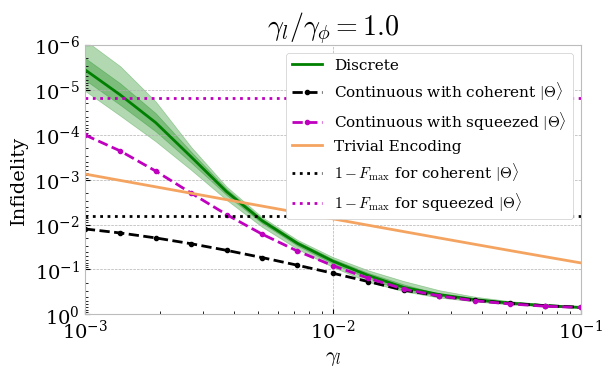

In [7]:
fig, ax = plt.subplots(dpi=100, figsize=(6.4, 3.5))
plot_break_even(ax, results_by_ratio[1], show_xlabel=True, show_legend=True)
save_figure(fig, "continuous_vs_discrete_alpha=7_gamma_l_over_gamma_phi=1")
plt.show()

/home/shoham/projects/BosonicEntanglementDistillation/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/shoham/projects/BosonicEntanglementDistillation/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


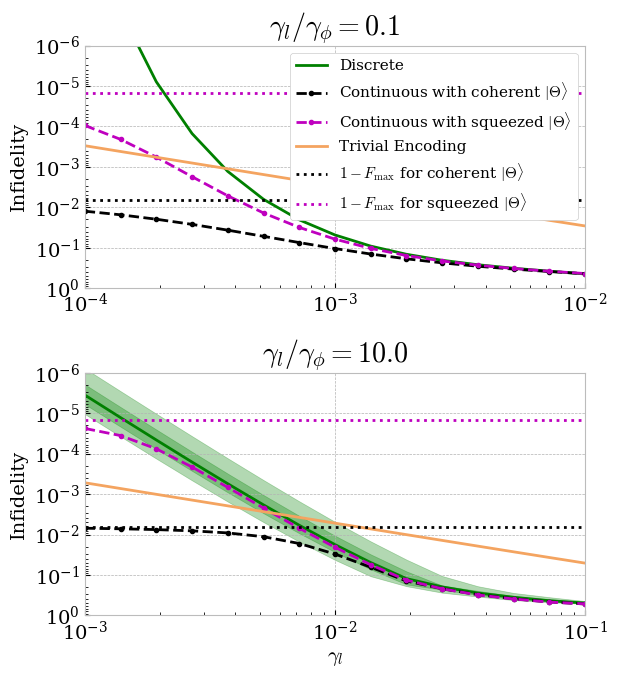

In [8]:
fig, axs = plt.subplots(2, 1, dpi=100, figsize=(6.4, 7.0), sharex=False)
plot_break_even(axs[0], results_by_ratio[0.1], show_xlabel=False, show_legend=True)
plot_break_even(axs[1], results_by_ratio[10], show_xlabel=True, show_legend=False)
fig.tight_layout()
save_figure(fig, "appendix_continuous_vs_discrete_alpha=7_gamma_l_over_gamma_phi=0p1_10")
plt.show()